Haidar Julien
ID: 2025-82987

My goal is : To what extent can the macroscopic behavior of a detonation that is interacting with a circular obstacle be reproduced using Euler equations and a simplified one-step chemical model ? 

To achieve this goal, I need to create first a 1D HLLC Riemann solver. Then couple it with a H2-air combustion. And then, once the 1D HLLC Riemann + combustion solver is ready, the code is extended to a 2D domain.

The following code is exactly the same as my code from Homework number 3 (Riemann).
I used Homework number 3 to validate my 1D HLLC solver. The change made in my code is replacing the Lax–Friedrichs scheme with the HLLC solver.

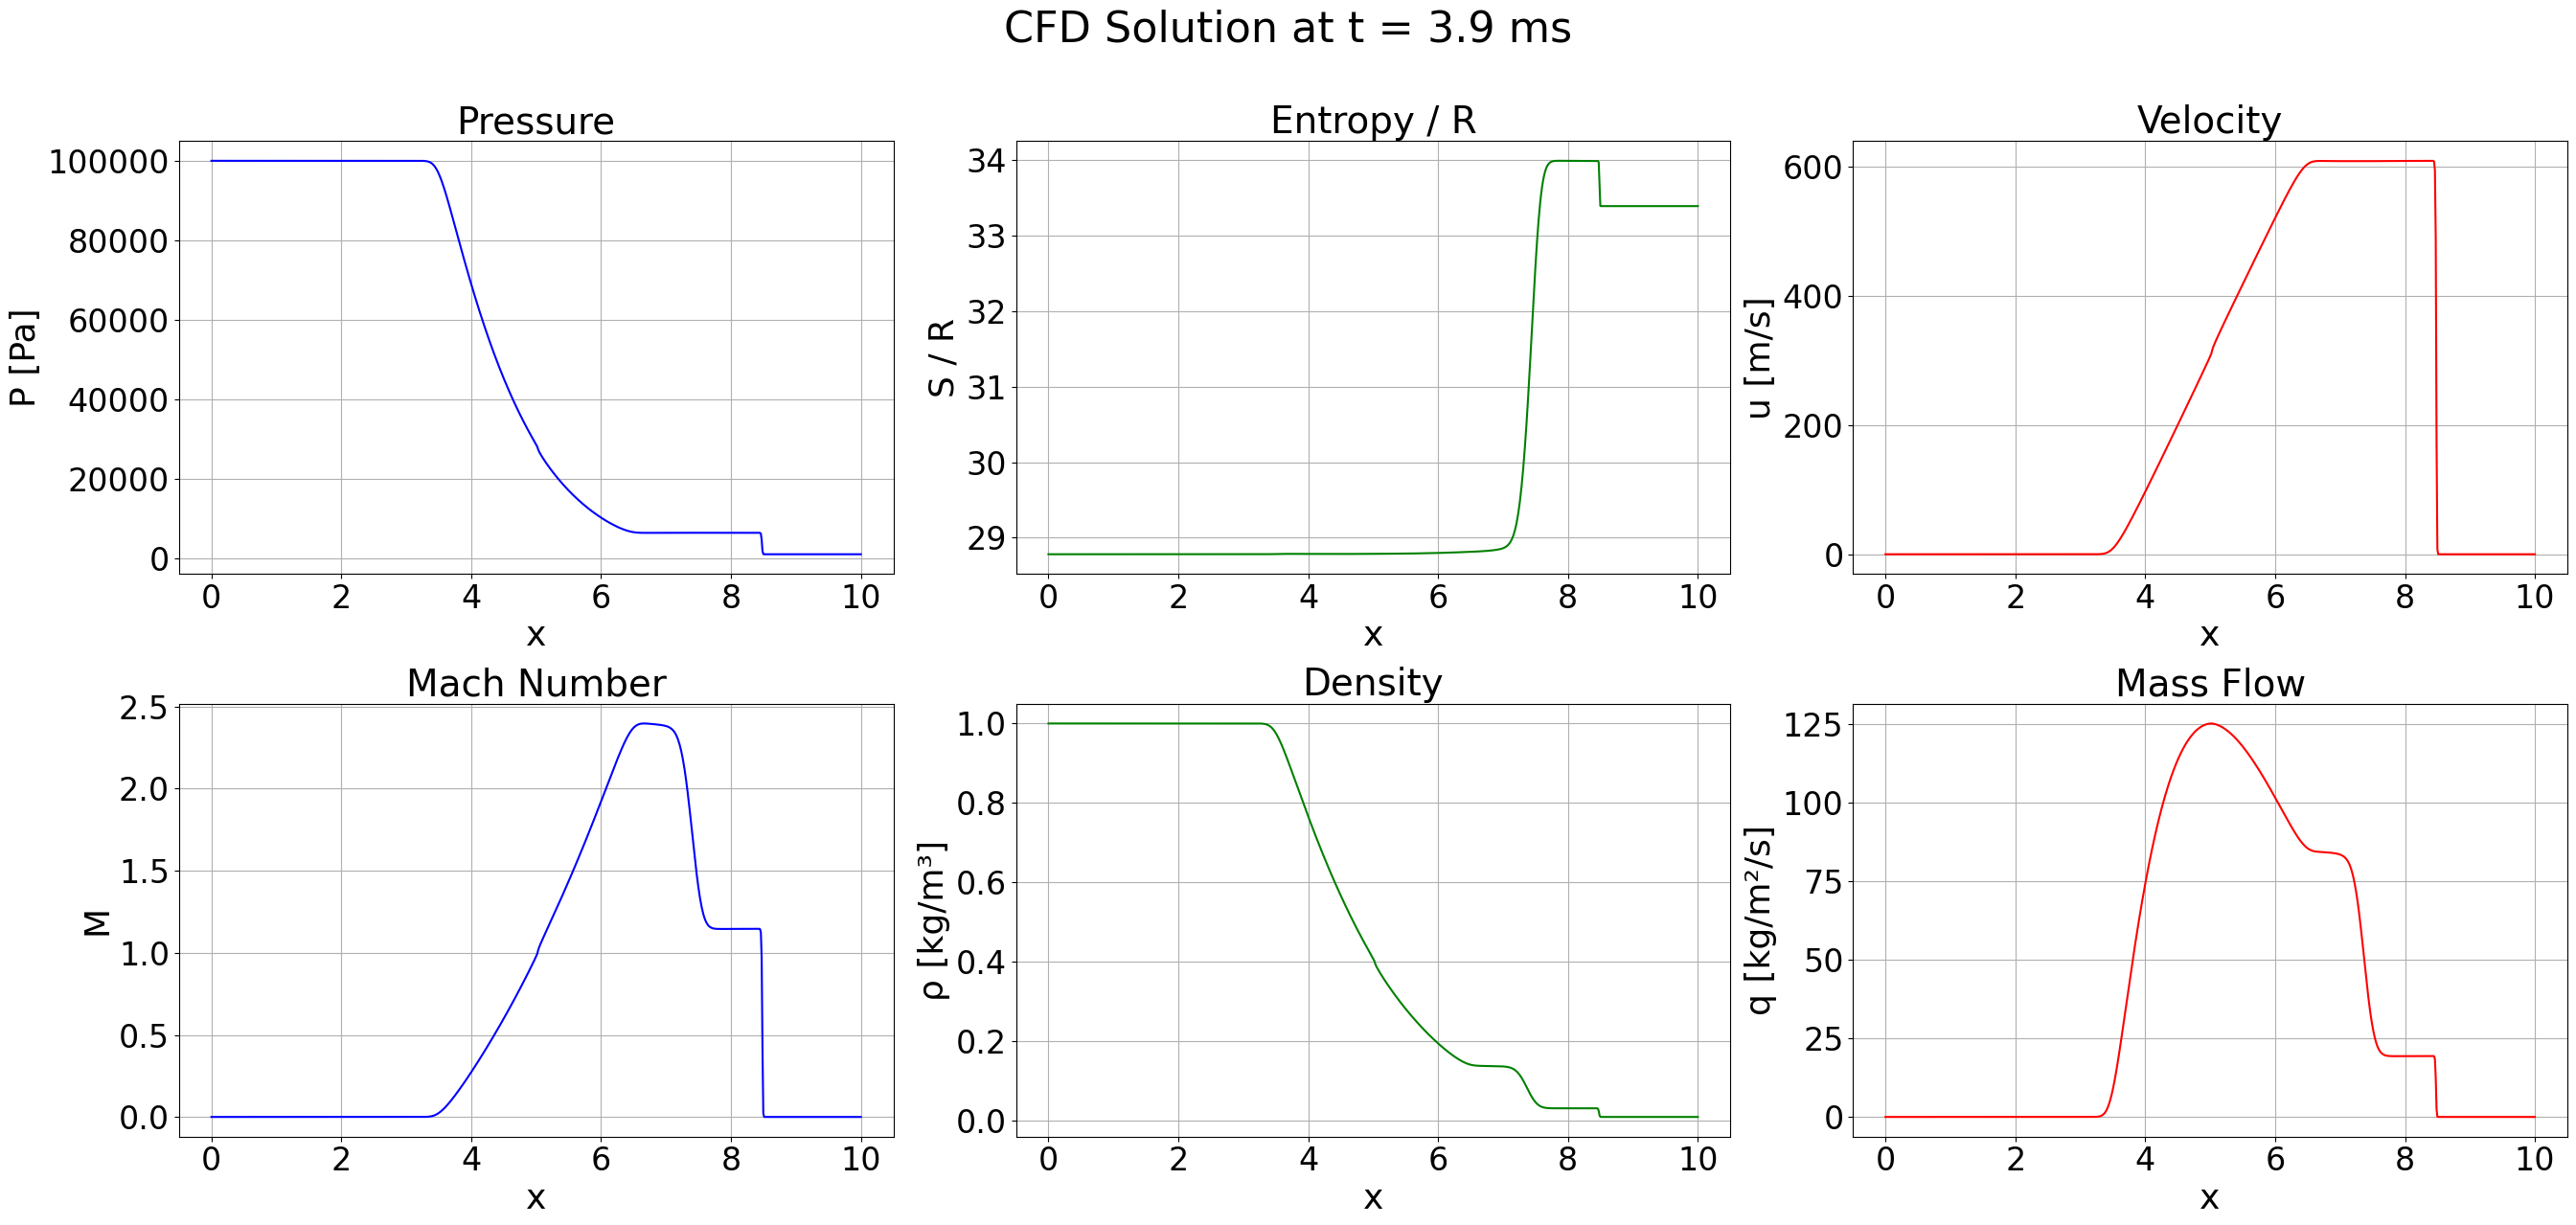

In [3]:
import numpy as np
import math as m
import matplotlib.pyplot as plt

#Space partitioning
Nx = 800
X = np.linspace(-5,5,Nx)
dx = X[1] - X[0]
CFL = 0.9

#Values of the given problem

#Left side of the tube
P_L = 10**5 #Pressure in N.m-2
p_L = 1 #Density in kg.m-3
u_L = 0 #Velocity in m.s-1

#Right side of the tube
P_R = 10**3 #Pressure in N.m-2
p_R = 0.01 #Density in kg.m-3
u_R = 0 #Velocity in m.s-1

#We are working with an ideal gas
gamma = 1.4
R = 287 #Nm/kgK

#Computing initial sound speed c, Mach number M, entropy/R S/R and mass flow q

#Left side of the tube
c_L = m.sqrt(gamma * P_L / p_L) #in m.s-1
M_L = u_L/c_L

S_L = R/(gamma - 1)*m.log(P_L / p_L**gamma) #in J.K-1

q_L = p_L*u_L #kg.m-2.s-1

#Right side of the tube
c_R = m.sqrt(gamma * P_R / p_R) #in m.s-1
M_R = u_R/c_R

S_R = R/(gamma - 1)*m.log(P_R / p_R**gamma) #in J.K-1

q_R = p_R*u_R #kg.m-2.s-1

#Space partitioning
X = np.linspace(-5,5,Nx)

#Computing the initial functions
P_init = np.where(X < 0, P_L, P_R)
p_init = np.where(X < 0, p_L, p_R)
S_init = R/(gamma - 1)*np.log(P_init/p_init**gamma)
u_init = np.where(X < 0, u_L, u_R)
c_init = np.where(X < 0, c_L, c_R)
M_init = u_init/c_init
q_init = p_init*u_init*1

#Creating Function U
def func_U(p, u, P):
    e = P/((gamma-1)*p) #specific internal energy
    E = 1/2*u**2 + e #Totale specific energy

    U0 = p
    U1 = p*u
    U2 = p*E

    return [U0, U1, U2]

#Creating Function FU
def func_FU(p, u, P):
    e = P/((gamma-1)*p) #specific internal energy
    E = 1/2*u**2 + e #Total specific energy

    FU0 = p*u
    FU1 = p*u**2 + P
    FU2 = (p*E + P)*u

    return [FU0, FU1, FU2]

#Getting the density from U
def func_p(U):
    return U[0]

#Getting the velocity from U
def func_u(U):
    return U[1]/U[0]

#Getting the pressure from U
def func_P(U):
    return (gamma-1)*U[0]*(U[2]/U[0] - 1/2*func_u(U)**2)

#Getting the speed of sound c from U
def func_c(U):
    return np.sqrt(gamma*func_P(U)/func_p(U))

import numpy as np


# ============================= Function HLLC_1D made by Gemini ========================================

def HLLC_1D(U_L: np.ndarray, U_R: np.ndarray, gamma: float) -> np.ndarray:
    """
    HLLC 1D Riemann Solver for the Euler Equations.

    Input:
        U_L, U_R: Conserved states as NumPy arrays [rho, rhou, rhoE].
        gamma: Ratio of specific heats (e.g., 1.4).
    Output:
        F_star: Numerical flux F* as a NumPy array [rho_u_flux, mom_normal_flux, E_flux].
    """

    # --- Auxiliary Function: Primitives and Exact Flux ---
    def conserve_to_primitives(U, gamma):
        """Calculates P, u, H, c, E from U."""
        rho, rhou, rhoE = U

        # Handle near-vacuum states for robustness
        if rho <= 1e-12 or rhoE <= 1e-12:
            return 1e-12, 0.0, 1e-12, 1e-6, 1e-12 # P, u, H, c, E

        u = rhou / rho
        E = rhoE / rho

        # Pressure P
        P = (gamma - 1) * (rhoE - 0.5 * rhou * u)
        if P <= 0: P = 1e-12 # Ensure positive pressure

        H = E + P / rho
        c = np.sqrt(gamma * P / rho)

        return P, u, H, c, E

    def state_to_flux(U, P, u, H):
        """Calculates the exact flux vector F(U). F = [rhou, rhou*u + P, rhou*H]"""
        return np.array([U[1], U[1] * u + P, U[1] * H])

    # --- 1. Compute Primitives and Boundary Fluxes ---
    P_L, u_L, H_L, c_L, E_L = conserve_to_primitives(U_L, gamma)
    P_R, u_R, H_R, c_R, E_R = conserve_to_primitives(U_R, gamma)

    F_L = state_to_flux(U_L, P_L, u_L, H_L)
    F_R = state_to_flux(U_R, P_R, u_R, H_R)

    # --- 2. Roe Averaging and Wave Speeds (S_L, S_R) ---
    sqrt_rho_L = np.sqrt(U_L[0])
    sqrt_rho_R = np.sqrt(U_R[0])

    u_bar = (sqrt_rho_L * u_L + sqrt_rho_R * u_R) / (sqrt_rho_L + sqrt_rho_R)
    H_bar = (sqrt_rho_L * H_L + sqrt_rho_R * H_R) / (sqrt_rho_L + sqrt_rho_R)
    c_bar = np.sqrt((gamma - 1) * (H_bar - 0.5 * u_bar**2))

    # HLL Wave Speeds (Einfeldt approach)
    S_L = min(u_L - c_L, u_bar - c_bar)
    S_R = max(u_R + c_R, u_bar + c_bar)

    # --- 3. Calculate Contact Wave Speed (S_M) ---
    T_L = U_L[0] * (S_L - u_L)
    T_R = U_R[0] * (S_R - u_R)

    S_M_num = P_R - P_L + T_L * u_L - T_R * u_R
    S_M_den = T_L - T_R

    # Calculate the Contact Wave Speed S_M
    S_M = S_M_num / S_M_den

    # --- 4. Trivial Cases (Single-sided wave) ---
    if S_L >= 0.0:
        return F_L, S_M
    if S_R <= 0.0:
        return F_R, S_M

    # Intermediate state Pressure P*
    P_star = P_L + T_L * (S_M - u_L)

    # --- 5. Flux Selection (F*_L or F*_R) ---

    if S_M >= 0.0:
        # Flux is F*_L (Left-Star)
        rho_L_star = T_L / (S_L - S_M)
        E_L_star = E_L + (P_star / rho_L_star - P_L / U_L[0]) / (S_L - S_M)

        U_L_star = np.array([rho_L_star, rho_L_star * S_M, rho_L_star * E_L_star])

        # F* = F_L + S_L * (U*_L - U_L)
        F_star = F_L + S_L * (U_L_star - U_L)
        return F_star, S_M

    else:
        # Flux is F*_R (Right-Star)
        rho_R_star = T_R / (S_R - S_M)
        E_R_star = E_R + (P_star / rho_R_star - P_R / U_R[0]) / (S_R - S_M)

        U_R_star = np.array([rho_R_star, rho_R_star * S_M, rho_R_star * E_R_star])

        # F* = F_R + S_R * (U*_R - U_R)
        F_star = F_R + S_R * (U_R_star - U_R)
        return F_star, S_M
# ============================= Function HLLC_1D made by Gemini ========================================

#U at the left side of the tube
U_L = func_U(p_L, u_L, P_L)

#U at the Right side of the tube
U_R = func_U(p_R, u_R, P_R)

#Initiale conditions
U_initial = func_U(p_init, u_init, P_init)

#U at the left side of the tube
U_L = func_U(p_L, u_L, P_L)

#U at the Right side of the tube
U_R = func_U(p_R, u_R, P_R)

#Initiale conditions
U_initial = func_U(p_init, u_init, P_init)

#Time
t_final = 3.9*10**(-3)
t = 0

U_past = U_initial.copy()

U = [np.zeros(Nx), np.zeros(Nx), np.zeros(Nx)]

while t < t_final:

    #Boundary condition for i = 0, U(0, t) = U_L
    U[0][0] = U_L[0]
    U[1][0] = U_L[1]
    U[2][0] = U_L[2]

    #CFL condition
    dt = CFL*dx/np.max(np.abs(func_u(U_past)) + np.abs(func_c(U_past))) #Computing dt to respect the CFL condition

    #Computing F(U)
    F = func_FU(func_p(U_past), func_u(U_past), func_P(U_past))

    for i in range(1, Nx - 1):



        # ============================= New by me ========================================
        #Computing fluxes from HLLC
        U_LL = np.array([U_past[0][i-1], U_past[1][i-1], U_past[2][i-1]])
        U_UU = np.array([U_past[0][i], U_past[1][i], U_past[2][i]])
        U_RR = np.array([U_past[0][i+1], U_past[1][i+1], U_past[2][i+1]])

        F_star_L, _ = HLLC_1D(U_LL, U_UU, gamma)
        F_star_R, _ = HLLC_1D(U_UU, U_RR, gamma)

        U[0][i] =  U_past[0][i] - dt/(dx) * (F_star_R[0] - F_star_L[0])
        U[1][i] =  U_past[1][i] - dt/(dx) * (F_star_R[1]- F_star_L[1])
        U[2][i] =  U_past[2][i] - dt/(dx) * (F_star_R[2] - F_star_L[2])
        # ============================= New by me ========================================



    #Boundary condition for i = Nx - 1, U(10, t) = U_R
    U[0][Nx - 1] = U_R[0]
    U[1][Nx - 1] = U_R[1]
    U[2][Nx - 1] = U_R[2]

    #Updating the past
    U_past = [U[0].copy(), U[1].copy(), U[2].copy()]

    t += dt

#Computing all the values needed to plot the results

p_CFD = func_p(U)
P_CFD = func_P(U)
u_CFD = func_u(U)
c_CFD = func_c(U)
M_CFD = u_CFD/c_CFD
S_CFD = R/(gamma - 1)*np.log(P_CFD/p_CFD**gamma)
q_CFD = p_CFD*u_CFD

#Plotting the results
label_fontsize = 26
title_fontsize = 28
tick_fontsize = 24
suptitle_fontsize = 32

fig, axs = plt.subplots(2, 3, figsize=(27, 13))
X_plot = X + 5
axs[0, 0].plot(X_plot, P_CFD, color='blue')
axs[0, 0].set_xlabel("x", fontsize=label_fontsize)
axs[0, 0].set_ylabel("P [Pa]", fontsize=label_fontsize)
axs[0, 0].set_title("Pressure", fontsize=title_fontsize)
axs[0, 0].tick_params(labelsize=tick_fontsize)
axs[0, 0].grid()

axs[0, 1].plot(X_plot, S_CFD / R, color='green')
axs[0, 1].set_xlabel("x", fontsize=label_fontsize)
axs[0, 1].set_ylabel("S / R", fontsize=label_fontsize)
axs[0, 1].set_title("Entropy / R", fontsize=title_fontsize)
axs[0, 1].tick_params(labelsize=tick_fontsize)
axs[0, 1].grid()

axs[0, 2].plot(X_plot, u_CFD, color='red')
axs[0, 2].set_xlabel("x", fontsize=label_fontsize)
axs[0, 2].set_ylabel("u [m/s]", fontsize=label_fontsize)
axs[0, 2].set_title("Velocity", fontsize=title_fontsize)
axs[0, 2].tick_params(labelsize=tick_fontsize)
axs[0, 2].grid()

axs[1, 0].plot(X_plot, M_CFD, color='blue')
axs[1, 0].set_xlabel("x", fontsize=label_fontsize)
axs[1, 0].set_ylabel("M", fontsize=label_fontsize)
axs[1, 0].set_title("Mach Number", fontsize=title_fontsize)
axs[1, 0].tick_params(labelsize=tick_fontsize)
axs[1, 0].grid()

axs[1, 1].plot(X_plot, p_CFD, color='green')
axs[1, 1].set_xlabel("x", fontsize=label_fontsize)
axs[1, 1].set_ylabel("ρ [kg/m³]", fontsize=label_fontsize)
axs[1, 1].set_title("Density", fontsize=title_fontsize)
axs[1, 1].tick_params(labelsize=tick_fontsize)
axs[1, 1].grid()

axs[1, 2].plot(X_plot, q_CFD, color='red')
axs[1, 2].set_xlabel("x", fontsize=label_fontsize)
axs[1, 2].set_ylabel("q [kg/m²/s]", fontsize=label_fontsize)
axs[1, 2].set_title("Mass Flow", fontsize=title_fontsize)
axs[1, 2].tick_params(labelsize=tick_fontsize)
axs[1, 2].grid()

plt.suptitle("CFD Solution at t = 3.9 ms", fontsize=suptitle_fontsize)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

The result is correct and even better than with the Lax–Friedrichs scheme I previously used in the homework. Thanks to Homework 3, I can move on to the next step, since now I am sure that my 1D HLLC solver is working. 

Now, some chemistry has to be added: H2 + 0.5*O2 -> H2O with only one step. To confirm that the coupling between chemistry and flow is correct, a detonation will be simulated.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from numba import njit
import time

# ==============================================================================
# 1. PARAMETERS
# ==============================================================================
Nx = 2000
L_domain = 1.0
x_start, x_end = 0.0, L_domain
CFL = 0.4
t_final = 0.5e-3

gamma = 1.4
R_gas = 287.0

# --- Specific Heat Capacities [J/kg/K] ---
CV_H2  = 10000.0
CV_O2  = 700.0
CV_N2  = 743.0
CV_H2O = 1500.0

Q_react = 7.0e6      # Heat Release [J/kg]
E_act = 4.0e6        # Activation Energy
Pre_Exp = 1.5e10     # Pre-exponential factor
T_ign_threshold = 800.0  # Ignition threshold

# Initial Conditions (Atmosphere)
P_atm = 101325.0
T_atm = 800.0
Y_H2_init = 0.029
Y_O2_init = 0.226
Y_N2_init = 0.745
Y_H2O_init = 0.0

# DETONATION KERNEL (Blast Start)
x_kernel = 0.05
T_kernel = 3500.0
P_kernel = 60.0 * P_atm

# ==============================================================================
# 2. FUNCTIONS (JIT COMPILED)
# ==============================================================================

@njit(cache=True, fastmath=True)
def get_primitives_7eq(U_state, gamma):
    """
    From U vector -> Primitive variables.
    U = [rho, rho*u, rho*E, rho*Y_i...]
    """
    rho = U_state[0]
    if rho <= 1e-12: rho = 1e-12

    # --- Extract Species for Cv_mix ---
    Y_H2  = U_state[3] / rho
    Y_O2  = U_state[4] / rho
    Y_H2O = U_state[5] / rho
    Y_N2  = U_state[6] / rho

    # Calculate Mixture Cv
    Cv_mix = Y_H2*CV_H2 + Y_O2*CV_O2 + Y_H2O*CV_H2O + Y_N2*CV_N2
    if Cv_mix < 500.0: Cv_mix = 500.0 # Safety floor

    u = U_state[1] / rho
    E = U_state[2] / rho
    e_int = E - 0.5 * u**2

    # floor internal energy to prevent negative pressure
    if e_int < 10.0: e_int = 10.0

    # T = e / Cv (Modified to use Cv_mix)
    T = e_int / Cv_mix

    # P = rho * R * T
    P = rho * R_gas * T

    # Local gamma for sound speed
    gamma_loc = 1.0 + R_gas / Cv_mix
    c = np.sqrt(gamma_loc * P / rho)
    H = E + P / rho

    return rho, u, P, T, c, H

@njit(cache=True, fastmath=True)
def compute_hllc_flux_7eq(U_L, U_R, gamma):
    """
    Computes the HLLC Numerical Flux at the interface.
    Robust Riemann solver for contact discontinuities.
    """
    rho_L, u_L, P_L, T_L, c_L, H_L = get_primitives_7eq(U_L, gamma) # Added T_L retrieval
    rho_R, u_R, P_R, _, c_R, H_R = get_primitives_7eq(U_R, gamma)

    F_L = np.empty(7); F_R = np.empty(7)

    # Standard Physical Fluxes F(U)
    F_L[0]=U_L[1]; F_L[1]=U_L[1]*u_L+P_L; F_L[2]=U_L[1]*H_L; F_L[3:]=U_L[3:]*u_L
    F_R[0]=U_R[1]; F_R[1]=U_R[1]*u_R+P_R; F_R[2]=U_R[1]*H_R; F_R[3:]=U_R[3:]*u_R

    # Wave Speed Estimates (Roe Averages)
    sqrt_rho_L = np.sqrt(rho_L); sqrt_rho_R = np.sqrt(rho_R)
    inv_den = 1.0 / (sqrt_rho_L + sqrt_rho_R)
    u_bar = (sqrt_rho_L*u_L + sqrt_rho_R*u_R)*inv_den
    H_bar = (sqrt_rho_L*H_L + sqrt_rho_R*H_R)*inv_den

    # Approx Gamma for Roe average (using T_L from variable Cv function)
    gamma_avg = 1.4
    c_bar = np.sqrt((gamma_avg-1.0)*(H_bar - 0.5*u_bar**2))

    S_L = min(u_L - c_L, u_bar - c_bar)
    S_R = max(u_R + c_R, u_bar + c_bar)

    # Supersonic cases
    if S_L >= 0.0: return F_L
    if S_R <= 0.0: return F_R

    # Subsonic cases (Star Region)
    K_L = rho_L*(S_L - u_L)
    K_R = rho_R*(S_R - u_R)

    denom = K_L - K_R
    if abs(denom) < 1e-10: return F_L

    S_star = (P_R - P_L + K_L*u_L - K_R*u_R) / denom
    P_star = P_L + K_L*(S_star - u_L)

    if S_star >= 0.0:
        factor = 1.0/(S_L - S_star)
        rho_star = K_L * factor
        U_star = np.empty(7)
        U_star[0] = rho_star
        U_star[1] = rho_star * S_star
        U_star[2] = rho_star * ((U_L[2]/rho_L) + (S_star - u_L)*(S_star + P_L/(rho_L*(S_L - u_L))))
        U_star[3:] = U_L[3:] * (rho_star/rho_L)
        return F_L + S_L * (U_star - U_L)
    else:
        factor = 1.0/(S_R - S_star)
        rho_star = K_R * factor
        U_star = np.empty(7)
        U_star[0] = rho_star
        U_star[1] = rho_star * S_star
        U_star[2] = rho_star * ((U_R[2]/rho_R) + (S_star - u_R)*(S_star + P_R/(rho_R*(S_R - u_R))))
        U_star[3:] = U_R[3:] * (rho_star/rho_R)
        return F_R + S_R * (U_star - U_R)

@njit(cache=True, fastmath=True)
def chemistry_step_implicit(U, dt):
    """
    Solves the stiff chemical source term using Newton-Raphson.
    Includes numerical derivative calculation.
    """
    Nx = U.shape[1]
    U_new = np.copy(U)
    max_iter = 8

    for i in range(Nx):
        rho = U[0, i]
        if rho <= 1e-9: continue
        rhoE = U[2, i]

        # --- Species for Cv calc ---
        Y_H2 = U[3, i]/rho; Y_O2 = U[4, i]/rho
        Y_H2O = U[5, i]/rho; Y_N2 = U[6, i]/rho

        # --- Calculate Initial Cv ---
        Cv_curr = Y_H2*CV_H2 + Y_O2*CV_O2 + Y_H2O*CV_H2O + Y_N2*CV_N2
        if Cv_curr < 500.0: Cv_curr = 500.0

        ec = 0.5 * (U[1, i]/rho)**2
        e_int_base = (rhoE/rho - ec)

        # --- temperature ---
        T_start = e_int_base / Cv_curr

        # Skip if not enough fuel or too cold
        if Y_H2 < 1e-6 or T_start < T_ign_threshold: continue

        Y_H2_new = Y_H2
        for k in range(max_iter):
            # Current state
            dY = Y_H2 - Y_H2_new
            Y_O2_curr = Y_O2 - 8.0 * dY
            if Y_O2_curr < 0: Y_O2_curr = 0

            # --- Update Y_H2O for Cv calc ---
            Y_H2O_curr = Y_H2O + 9.0 * dY

            # --- Update Cv based on new composition ---
            Cv_new = Y_H2_new*CV_H2 + Y_O2_curr*CV_O2 + Y_H2O_curr*CV_H2O + Y_N2*CV_N2
            if Cv_new < 500.0: Cv_new = 500.0

            # Conservation of Energy: e_new = e_base + Q*dY
            T_curr = (e_int_base + Q_react * dY) / Cv_new

            # Arrhenius Rate
            w = Pre_Exp * rho * Y_H2_new * Y_O2_curr * np.exp(-E_act/(R_gas*T_curr))

            # Function to zero: Y_new - Y_old + (w/rho)*dt = 0
            g = Y_H2_new - Y_H2 + (w/rho)*dt

            # Numerical Derivative (Perturbation)
            delta = 1e-7
            Y_p = Y_H2_new + delta
            dY_p = Y_H2 - Y_p

            # --- Perturbed Cv ---
            Y_O2_p = Y_O2 - 8.0*dY_p
            Y_H2O_p = Y_H2O + 9.0*dY_p
            Cv_p = Y_p*CV_H2 + Y_O2_p*CV_O2 + Y_H2O_p*CV_H2O + Y_N2*CV_N2
            if Cv_p < 500.0: Cv_p = 500.0

            # --- Perturbed T ---
            T_p = (e_int_base + Q_react * dY_p) / Cv_p

            w_p = Pre_Exp * rho * Y_p * (Y_O2 - 8.0*dY_p) * np.exp(-E_act/(R_gas*T_p))
            g_p = Y_p - Y_H2 + (w_p/rho)*dt

            dg = (g_p - g)/delta

            if abs(dg) < 1e-15: break
            dY_N = -g/dg
            Y_H2_new += dY_N

            # Clipping (From Gemini)
            if Y_H2_new < 0: Y_H2_new = 0
            if Y_H2_new > Y_H2: Y_H2_new = Y_H2
            if abs(dY_N) < 1e-6: break

        # Apply changes to U vector
        dY_fin = Y_H2 - Y_H2_new

        # --- Update ---
        e_int_final = e_int_base + Q_react*dY_fin
        U_new[2, i] = rho * (e_int_final + ec)

        U_new[3, i] = rho * Y_H2_new
        U_new[4, i] = rho * (Y_O2 - 8.0*dY_fin)
        U_new[5, i] = rho * (U[5, i]/rho + 9.0*dY_fin)

    return U_new

@njit(cache=True, fastmath=True)
def hydro_step_1d(U, dx, dt, gamma):
    """
    Standard 1D Hydrodynamic Step (No Obstacle).
    Finite Volume Method: U_new = U - dt/dx * (F_R - F_L)
    """
    Nx = U.shape[1]
    Fluxes = np.zeros((7, Nx + 1))
    U_new = np.copy(U)

    # 1. Compute HLLC Fluxes at interfaces
    for i in range(Nx - 1):
        Fluxes[:, i+1] = compute_hllc_flux_7eq(U[:, i], U[:, i+1], gamma)

    # 2. Update Cells (Divergence of Flux)
    for i in range(1, Nx - 1):
        flux_div = (Fluxes[:, i+1] - Fluxes[:, i]) / dx
        U_new[:, i] = U[:, i] - dt * flux_div

    # Boundary Conditions (Reflective Wall at Left, Open at Right)
    U_new[:, 0] = U_new[:, 1]; U_new[1, 0] = -U_new[1, 1]
    U_new[:, -1] = U_new[:, -2]

    return U_new

# ==============================================================================
# MAIN
# ==============================================================================
X = np.linspace(x_start, x_end, Nx)
dx = X[1] - X[0]
U = np.zeros((7, Nx))

# Initialization

Cv_init_mix = Y_H2_init*CV_H2 + Y_O2_init*CV_O2 + Y_H2O_init*CV_H2O + Y_N2_init*CV_N2

for i in range(Nx):
    if X[i] < x_kernel:
        T_loc = T_kernel; P_loc = P_kernel
    else:
        T_loc = T_atm; P_loc = P_atm

    rho_loc = P_loc / (R_gas * T_loc)
    U[0, i] = rho_loc
    U[1, i] = 0.0

    U[2, i] = rho_loc * Cv_init_mix * T_loc
    U[3, i] = rho_loc * Y_H2_init
    U[4, i] = rho_loc * Y_O2_init
    U[5, i] = 0.0
    U[6, i] = rho_loc * Y_N2_init

# Plotting Setup (Made By GEMINI)
plt.ion()
# Changed to 4 rows to include species
fig, (ax1, ax2, ax3, ax5, ax4) = plt.subplots(5, 1, figsize=(10, 14), sharex=True)

# Temperature Plot
line_T, = ax1.plot(X, np.zeros(Nx), 'r-', linewidth=1.5)
ax1.set_ylabel('Temperature [K]')
ax1.set_title('1D Detonation Propagation (T, P, Mach, Species)')
ax1.set_ylim(200, 4000)
ax1.grid(True, alpha=0.3)

# Pressure Plot
line_P, = ax2.plot(X, np.zeros(Nx), 'b-', linewidth=1.5)
ax2.set_ylabel('Pressure [Pa]')
ax2.grid(True, alpha=0.3)

# Mach Plot
line_M, = ax3.plot(X, np.zeros(Nx), 'g-', linewidth=1.5)
ax3.set_ylabel('Mach Number (Lab)')
ax3.grid(True, alpha=0.3)
ax3.axhline(1.0, color='k', linestyle='--', alpha=0.5, label='M=1 (Sonic)')
ax3.legend(loc='upper right')

# Speed Plot
line_V, = ax5.plot(X, np.zeros(Nx), 'g-', linewidth=1.5)
ax5.set_ylabel('Speed')
ax5.grid(True, alpha=0.3)

# Species Plot
line_H2, = ax4.plot(X, np.zeros(Nx), label='H2', color='orange')
line_O2, = ax4.plot(X, np.zeros(Nx), label='O2', color='cyan')
line_H2O, = ax4.plot(X, np.zeros(Nx), label='H2O', color='purple')
line_N2, = ax4.plot(X, np.zeros(Nx), label='N2', color='gray', linestyle='--')
# Sum of Species Line
line_Sum, = ax4.plot(X, np.zeros(Nx), label='Sum', color='black', linestyle=':', linewidth=1.5)

ax4.set_ylabel('Mass Fraction Yi')
ax4.set_xlabel('Position x [m]')
ax4.set_ylim(0, 1.1) # Up to 1.1 to see Sum=1 line
ax4.legend(loc='center right')
ax4.grid(True, alpha=0.3)

t = 0.0; it = 0
print("Starting 1D Detonation Simulation...")

while t < t_final:
    # CFL Condition
    rho = U[0]; u = U[1]/rho; P = (gamma-1)*(U[2]-0.5*rho*u**2)
    c = np.sqrt(gamma*np.abs(P)/rho)
    dt = CFL * dx / np.max(np.abs(u)+c)

    # Strang Splitting (Hydro -> Chemistry -> Hydro)
    U = hydro_step_1d(U, dx, dt*0.5, gamma)
    U = chemistry_step_implicit(U, dt)
    U = hydro_step_1d(U, dx, dt*0.5, gamma)

    t += dt; it += 1

    # Visualization Loop (Made by GEMINI)
    if it % 10 == 0:
        rho_p = U[0]
        u_p = U[1]/rho_p

        Y_H2_p = U[3]/rho_p
        Y_O2_p = U[4]/rho_p
        Y_H2O_p = U[5]/rho_p
        Y_N2_p = U[6]/rho_p

        # Temperature
        Cv_field = Y_H2_p*CV_H2 + Y_O2_p*CV_O2 + Y_H2O_p*CV_H2O + Y_N2_p*CV_N2
        e_int_p = U[2]/rho_p - 0.5*u_p**2
        T_p = e_int_p / Cv_field

        # Pressure
        P_p = rho_p * R_gas * T_p

        # Calculate Mach
        # Gamma also varies: gamma = 1 + R/Cv
        gamma_field = 1.0 + R_gas / Cv_field
        c_p = np.sqrt(gamma_field * P_p / rho_p)
        M_p = np.abs(u_p) / c_p

        # Calculate Sum
        Sum_p = Y_H2_p + Y_O2_p + Y_H2O_p + Y_N2_p

        line_T.set_ydata(T_p)
        line_P.set_ydata(P_p)
        line_M.set_ydata(M_p)
        line_V.set_ydata(u_p)

        # Update Species Lines
        line_H2.set_ydata(Y_H2_p)
        line_O2.set_ydata(Y_O2_p)
        line_H2O.set_ydata(Y_H2O_p)
        line_N2.set_ydata(Y_N2_p)
        line_Sum.set_ydata(Sum_p)

        # Auto-scale Pressure
        current_max_P = np.max(P_p)
        if current_max_P > ax2.get_ylim()[1]:
            ax2.set_ylim(0, current_max_P * 1.2)

        # Auto-scale Mach
        current_max_M = np.max(M_p)
        if current_max_M > ax3.get_ylim()[1]:
            ax3.set_ylim(0, current_max_M * 1.2)

        # Auto-scale Speed
        current_max_V = np.max(u_p)
        current_min_V = np.min(u_p)
        if current_max_V > ax5.get_ylim()[1]:
            ax5.set_ylim(current_min_V * 1.2, current_max_V * 1.2)

        fig.canvas.draw()
        fig.canvas.flush_events()

plt.ioff()
plt.show()
print("Simulation Complete.")

Starting 1D Detonation Simulation...


In this new code, Gemini did all of the plotting/animation and wrote the initial conditions and the domain. To see the animation, the code has to be executed outside Jupyter with edupython or spider for example.

Also, to make the simulation process faster, Numpa has been used and added by Gemini.

To handle the computationally intensive loops of the Riemann solver, the @njit decorator is applied. This enforces the 'nopython mode' to be sure that the code is compiled entirely to native machine instructions without the intervention of the Python interpreter. Thus, the speed is comparable to language C or Fortran.

In this simulation, the chemistry step is achieved with Implicit Euler scheme.
Strang splitting has been also used : Combustion step dt/2 --> Flow step dt --> Combustion step dt/2


The ambiant initial condition is P_atm = 101325.0 (Pa) and T_atm = 800.0 (K) (to make the detonation more powerful).
In all of the cells, there is Y_H2_init = 0.029, Y_O2_init = 0.226, Y_N2_init = 0.745 and Y_H2O_init = 0.0.
For the blast, it is ignited at x_kernel = 0.05 with T_kernel = 3500.0 and P_kernel = 60.0 * P_atm
The gas is supposed to be an ideal gaz.

With these results, we can see that the flow solver is still working properly even in the presence of combustion. 

A Taylor-type rarefaction is observed in the temperature, pressure, and velocity fields. However, this is not a pure Taylor rarefaction, because chemical reactions are present. A classical Taylor rarefaction corresponds to a purely gas-dynamic flow without any combustion. And the most important point is that the sum of the mass fractions is equal to one over the entire domain. There is no creation or disappearance of mass. The species mass is conserved.

From the animation, the detonation front appears to propagate at an approximately constant speed over the observed time interval. The front propagates supersonically with a Mach number of about 1.40 relative to the front. The chemical reactions contribute to sustaining the high speed propagation of the fro by giving thermal energyntThe slight decrease in the front speed is expected. Since the finite initial energy is spreading over a larger volume, it is reducing the available energy density.y.

Finally, we really observe a detonation. If you watch the animation, the flame front and the shock wave front have the same position throughout the entire simulation. No signal propagates ahead of the detonation front, so the initial gas state is still observed upstream of the detonation.

And the most important thing is the simulation did not blow up. It is very stable. That was expected because implicit euler scheme has been used for the combustion. To enhance this simulation, more cells should be added to the grid. If the cells are too large, some physic phenomena like the von Neumann spike (immediately behind the leading shock) cannot be captured on the graph. However, the von Neumann spike does not appear in my results because the combustion mechanism is maybe not adapted or there are not enough cells.

The next code is an extension to 2D domain of the previous 1D HLLC + combustion solver. This time, the flow step is achieved with explicit RK2 scheme and the chemistry step is achieved with implicit Crank-Nicolson scheme.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from numba import njit
import time

In [ ]:
# ==============================================================================
# A. CONFIGURATION CONSTANTS
# ==============================================================================

# 1. Geometry & Grid
LX, LY = 0.20, 0.10 #in meter [m]
NX, NY = 200, 100
DX, DY = LX / NX, LY / NY

# 2. Simulation Control
CFL = 0.3
T_FINAL = 3.5e-4

# 3. Gas Properties (Ideal Gas Law)
GAMMA = 1.4
R_GAS = 287.0

CV_H2  = 10000.0
CV_O2  = 700.0
CV_N2  = 743.0
CV_H2O = 1500.0

# 4. Chemistry (Arrhenius Parameters for H2 + 0.5 O2 -> H2O)
Q_REACT = 7.0e6      # Heat Release [J/kg]
E_ACT = 4.0e6        # Activation Energy [J/kg]
PRE_EXP = 1.5e10     # Pre-exponential Factor [Hz]
T_IGN_THRESHOLD = 800.0

# 5. Initialization
P_ATM, T_ATM = 101325.0, 295.0
P_BLAST, T_BLAST = 80.0 * P_ATM, 3500.0
R_BLAST = 0.025
# Mass Fractions: [H2, O2, H2O, N2]
Y_INIT = np.array([0.029, 0.226, 0.0, 0.745])

# 6. Obstacle (Cylinder)
X_CYL, Y_CYL, R_CYL = 0.08, 0.05, 0.015

We assume that the gas is an ideal gas.

For chemistry, the reaction H₂ + 0.5*O₂ → H₂O is used with only one step (Arrhenius).
To avoid useless chemistry steps, T_IGN_THRESHOLD is defined as the minimum temperature at which the chemistry is applied.
This is because, for the processor, computing an exponential is costly. Thus, we avoid useless exponentials that are effectively zero, such as e^(-50).

The domain is rectangular with LX = 20 cm and LY = 10 cm.

To initiate a detonation, the blast pressure is 80 bar and the blast temperature is 3500 K with a radius of 2.5 cm. The position of the detonation is x = 0 and y = LY/2. The obstacle is a cylinder at x = 0.08, y = LY/2 with a radius of 1.5 cm

In [ ]:
# ==============================================================================
# B. THERMODYNAMICS MODULE (Equation of State)
# ==============================================================================

@njit(cache=True, fastmath=True)
def get_temperature_from_energy(rho, rhou, rhov, rhoE, Cv_local):
    """
    Since the gas is assumed ideal, T is computed with the Ideal Gas Law:
    e = E_total - E_kinetic
    T = e / Cv
    """
    if rho <= 1e-12: rho = 1e-12 #To avoid a division by zero.

    # Kinetic Energy density
    E_kin = 0.5 * (rhou**2 + rhov**2) / rho

    # Internal Energy density
    rho_e = rhoE - E_kin

    # Numerical floor for temperature to always have e > 1.0 to avoid e < 0 because of numerical/rounding errors in rho_e = rhoE - E_kin
    if rho_e < 1.0 * rho: rho_e = 1.0 * rho

    T = rho_e / (rho * Cv_local)
    return T

@njit(cache=True, fastmath=True)
def get_pressure(rho, T):
    """Equation of State: P = rho * R * T"""
    return rho * R_GAS * T

@njit(cache=True, fastmath=True)
def get_sound_speed(T, gamma_local):
    """Speed of sound: c = sqrt(gamma * R * T)"""
    return np.sqrt(gamma_local * R_GAS * T)

@njit(cache=True, fastmath=True)
def conservative_to_primitive(U):
    """
    From U -> Primitive variables.
    U = [rho, rhou, rhov, rhoE, rhoY...]
    """
    rho = U[0]
    u = U[1] / rho
    v = U[2] / rho

    Y_H2 = U[4] / rho
    Y_O2 = U[5] / rho
    Y_H2O = U[6] / rho
    Y_N2 = U[7] / rho

    Cv_mix = Y_H2*CV_H2 + Y_O2*CV_O2 + Y_H2O*CV_H2O + Y_N2*CV_N2
    if Cv_mix < 100.0: Cv_mix = 100.0

    T = get_temperature_from_energy(U[0], U[1], U[2], U[3], Cv_mix)
    P = get_pressure(rho, T)

    gamma_local = 1.0 + R_GAS / Cv_mix
    c = get_sound_speed(T, gamma_local)
    H = (U[3] + P) / rho # Total Enthalpy

    return rho, u, v, P, c, H, gamma_local

In [ ]:
# ==============================================================================
# C. PHYSICAL FLUX MODULE F(U)
# ==============================================================================

@njit(cache=True, fastmath=True)
def compute_physical_flux_F(U):
    """
    Computes the Euler Flux Vector F(U) in the X-direction.
    F(U) = [
        rho * u,
        rho * u^2 + P,
        rho * u * v,
        u * (rhoE + P),
        rho * u * Yi ...
    ]
    """
    rho, u, v, P, c, H, _ = conservative_to_primitive(U)

    F = np.empty(8)
    mass_flow = rho * u

    F[0] = mass_flow
    F[1] = mass_flow * u + P   # Momentum X
    F[2] = mass_flow * v       # Momentum Y (Transported)
    F[3] = mass_flow * H       # Energy

    # Species Transport
    F[4] = U[4] * u
    F[5] = U[5] * u
    F[6] = U[6] * u
    F[7] = U[7] * u

    return F

This function is at the same time F(U) flux or G(U) flux.

To have F(U) flux, we give the "normal" vector U = (rho, rho*u, rho*v, ...) (X-direction). To have G(U) flux, u and v are switched so U_switch = (rho, rho*v, rho*u, ...) (Y-direction)

In [ ]:
# ==============================================================================
# D. NUMERICAL FLUX MODULE (Riemann Solver)
# ==============================================================================

#solve_hllc_riemann() made by GEMINI
@njit(cache=True, fastmath=True)
def solve_hllc_riemann(U_L, U_R):
    """
    Computes the HLLC Numerical Flux at the interface between Left and Right states.
    """
    # 1. Primitives
    rho_L, u_L, v_L, P_L, c_L, H_L, gamma_L = conservative_to_primitive(U_L)
    rho_R, u_R, v_R, P_R, c_R, H_R, gamma_R = conservative_to_primitive(U_R)

    # 2. Wave Speed Estimation (Davis/Einfeldt simplified)
    # Roe Averages
    sqL, sqR = np.sqrt(rho_L), np.sqrt(rho_R)
    inv_den = 1.0 / (sqL + sqR)
    u_roe = (sqL*u_L + sqR*u_R) * inv_den
    v_roe = (sqL*v_L + sqR*v_R) * inv_den
    H_roe = (sqL*H_L + sqR*H_R) * inv_den

    gamma_roe = 0.5 * (gamma_L + gamma_R)
    c_roe = np.sqrt((gamma_roe-1)*(H_roe - 0.5*(u_roe**2 + v_roe**2)))

    S_L = min(u_L - c_L, u_roe - c_roe)
    S_R = max(u_R + c_R, u_roe + c_roe)

    # 3. Logic for Flux Selection

    # Case A: Supersonic Flow (Left to Right)
    if S_L >= 0.0:
        return compute_physical_flux_F(U_L)

    # Case B: Supersonic Flow (Right to Left)
    if S_R <= 0.0:
        return compute_physical_flux_F(U_R)

    # Case C: Subsonic (Star Region)
    # Contact Wave Speed S_star
    denom = (rho_L*(S_L - u_L)) - (rho_R*(S_R - u_R))
    if abs(denom) < 1e-10: return compute_physical_flux_F(U_L) # Fallback

    S_star = (P_R - P_L + rho_L*u_L*(S_L - u_L) - rho_R*u_R*(S_R - u_R)) / denom
    P_star = P_L + rho_L*(S_L - u_L)*(S_star - u_L)

    # HLLC Flux Assembly
    if S_star >= 0.0:
        # Left Star State U*_L
        rho_star = rho_L * (S_L - u_L) / (S_L - S_star)

        U_star = np.empty(8)
        U_star[0] = rho_star * 1.0
        U_star[1] = rho_star * S_star
        U_star[2] = rho_star * v_L  # Tangential velocity preserved
        U_star[3] = rho_star * (U_L[3]/rho_L + (S_star - u_L)*(S_star + P_L/(rho_L*(S_L - u_L))))
        U_star[4:] = U_L[4:] * (rho_star/rho_L)

        F_L = compute_physical_flux_F(U_L)
        return F_L + S_L * (U_star - U_L)

    else:
        # Right Star State U*_R
        rho_star = rho_R * (S_R - u_R) / (S_R - S_star)

        U_star = np.empty(8)
        U_star[0] = rho_star * 1.0
        U_star[1] = rho_star * S_star
        U_star[2] = rho_star * v_R
        U_star[3] = rho_star * (U_R[3]/rho_R + (S_star - u_R)*(S_star + P_R/(rho_R*(S_R - u_R))))
        U_star[4:] = U_R[4:] * (rho_star/rho_R)

        F_R = compute_physical_flux_F(U_R)
        return F_R + S_R * (U_star - U_R)

#solve_hllc_riemann() made by GEMINI

This HLLC Riemann solver will solve all of the horizontal and vertical lines of the 2D domain.
This function uses the previous function : compute_physical_flux_F.

In [ ]:
# ==============================================================================
# E. CHEMICAL SOURCE MODULE S(U)
# ==============================================================================

@njit(cache=True, fastmath=True)
def get_arrhenius_rate(rho, T, Y_H2, Y_O2):
    """
    Computes the reaction rate omega [kg/m3/s].
    Law: w = A * rho * Y_F * Y_Ox * exp(-Ea/RT)
    """
    if Y_H2 <= 1e-9 or T < T_IGN_THRESHOLD: #To avoid useless computations
        return 0.0

    return PRE_EXP * rho * Y_H2 * Y_O2 * np.exp(-E_ACT / (R_GAS * T))

@njit(cache=True, fastmath=True)
def get_source(rho, T, Y_H2, Y_O2):
    """
    Computes the source term s = dY_H2/dt [1/s].
    s(U) for mass fraction is: - omega / rho
    """
    # Rate of reaction [kg/m3/s]
    omega = get_arrhenius_rate(rho, T, Y_H2, Y_O2)

    # Rate of change of mass fraction: dY/dt = -w/rho
    # (Negative because H2 is consumed)
    S_H2 = -omega / rho

    return S_H2

@njit(cache=True, fastmath=True)
def chemistry_solver_crank_nicolson(U_cell, dt):
    """
    Integrates the stiff chemical source term using Crank-Nicolson + Newton.
    Solves: Y_new = Y_old + 0.5 * dt * (S(Y_old) + S(Y_new))
    """
    rho = U_cell[0]
    if rho < 1e-6: return U_cell # Vacuum check

    # 1. Unpack State (n)
    U_new = U_cell.copy()
    rhoE = U_cell[3]
    Y_H2_old = U_cell[4] / rho
    Y_O2_old = U_cell[5] / rho
    Y_H2O_old = U_cell[6] / rho
    Y_N2_old = U_cell[7] / rho

    Cv_old = Y_H2_old*CV_H2 + Y_O2_old*CV_O2 + Y_H2O_old*CV_H2O + Y_N2_old*CV_N2
    if Cv_old < 100.0: Cv_old = 100.0

    T_old = get_temperature_from_energy(rho, U_cell[1], U_cell[2], rhoE, Cv_old)

    # 2. Compute Source Term at state (n)
    # S_old is negative (consumption)
    S_old = get_source(rho, T_old, Y_H2_old, Y_O2_old)

    if S_old == 0.0: return U_cell # No reaction

    # 3. Newton-Raphson Loop to find Y_H2 at state (n+1)
    Y_H2_new = Y_H2_old
    max_iter = 6

    # Internal energy (kinetic subtracted)
    E_kin = 0.5 * (U_cell[1]**2 + U_cell[2]**2) / rho
    rho_e_initial = rhoE - E_kin

    for k in range(max_iter):
        # Calculate induced state changes based on current guess Y_H2_new
        dY = Y_H2_old - Y_H2_new # Amount of H2 consumed (positive)

        Y_O2_new = Y_O2_old - 8.0 * dY
        if Y_O2_new < 0: Y_O2_new = 0.0

        Y_H2O_new = Y_H2O_old + 9.0 * dY

        Cv_new = Y_H2_new*CV_H2 + Y_O2_new*CV_O2 + Y_H2O_new*CV_H2O + Y_N2_old*CV_N2
        if Cv_new < 100.0: Cv_new = 100.0

        # Energy conservation implies Temperature change
        # rho * e_new = rho * e_old + rho * Q * dY
        rho_e_new = rho_e_initial + rho * Q_REACT * dY
        T_new = rho_e_new / (rho * Cv_new)

        # Calculate Source Term at estimated state (n+1)
        S_new = get_source(rho, T_new, Y_H2_new, Y_O2_new)

        # Implicit Residual Function G(Y_new) = 0
        # Formula: Y_new - Y_old - 0.5 * dt * (S_old + S_new) = 0
        G = Y_H2_new - Y_H2_old - 0.5 * dt * (S_old + S_new)

        # --- Numerical Derivative dG/dY ---
        delta = 1e-7
        Y_H2_pert = Y_H2_new + delta

        # Perturbed State
        dY_pert = Y_H2_old - Y_H2_pert
        Y_O2_pert = Y_O2_old - 8.0 * dY_pert
        Y_H2O_pert = Y_H2O_old + 9.0 * dY_pert

        Cv_pert = Y_H2_pert*CV_H2 + Y_O2_pert*CV_O2 + Y_H2O_pert*CV_H2O + Y_N2_old*CV_N2
        if Cv_pert < 100.0: Cv_pert = 100.0

        rho_e_pert = rho_e_initial + rho * Q_REACT * dY_pert
        T_pert = rho_e_pert / (rho * Cv_pert)

        # Perturbed Source Term
        S_pert = get_source(rho, T_pert, Y_H2_pert, Y_O2_pert)

        # Perturbed Residual
        G_pert = Y_H2_pert - Y_H2_old - 0.5 * dt * (S_old + S_pert)

        dG = (G_pert - G) / delta

        if abs(dG) < 1e-15: break # Avoid division by zero

        # Newton Step
        Y_H2_new -= G / dG

        if abs(G) < 1e-7: break # Convergence reached

    # 4. Apply final changes to U Vector
    dY_total = Y_H2_old - Y_H2_new

    # Energy Source: d(rhoE) = rho * Q * dY
    U_new[3] += rho * Q_REACT * dY_total

    # Species Source: d(rhoY) = - rho * dY
    U_new[4] -= rho * dY_total       # H2
    U_new[5] -= rho * 8.0 * dY_total # O2
    U_new[6] += rho * 9.0 * dY_total # H2O

    return U_new

The equation is 1*H2 + 0.5*O2 -> 1*H2O.

The molar masses of H2, 0.5*O2 and H2O are:
    M_H2 = 2*1 g.mol-1
    M_0.5O2 = M_O = 16 g.mol-1
    M_H2O = 2 + 16 = 18 g.mol-1

Therefore, when there is a variation dY_H2 > 0 for H2 due to the combustion, dY_O2 = -8*dY_H2 and dY_H20 = 9*dY_H2.

In the cell, during the chemistry step (from Strang splitting method), there is no fluid motion so rho is constant.
Since rho is independent on time t, d(rho*Y_H2)/dt = -omega_H2 becomes dY_H2/dt = -omega_H2/rho.
We define G as G(Y) = Y - Y_H2_old - dt/2 * (S_old + S_new(Y))  (Crank-Nicolson)

Finite Difference Numerical Differentiation is used to compute G'(Y): dG/dY = (G(Y + delta) - G(Y))/delta.
Therefore, Y_H2 is pertubed and from this perturbation, it is possible to get the perturbation of Y_O2 and T thus S_pert.

In [ ]:
# ==============================================================================
# F. TIME INTEGRATION MODULE (RK2)
# ==============================================================================

@njit(cache=True, fastmath=True)
def compute_divergence_1D(U_line, dx, mask_line):
    """Calculates -dF/dx for a 1D line."""
    N = U_line.shape[1]
    RHS = np.zeros_like(U_line)
    Fluxes = np.zeros((8, N+1))

    # Compute Fluxes at interfaces
    for i in range(N - 1):
        U_L = U_line[:, i].copy()
        U_R = U_line[:, i+1].copy()


        #The boundary condition is applied to the line to have the right flux from HLLC function

        #Made by GEMINI
        # Wall Boundary Condition (Mirror) inside domain
        if mask_line[i] and not mask_line[i+1]:
            U_L = U_R.copy(); U_L[1] *= -1 # Invert normal velocity
        elif not mask_line[i] and mask_line[i+1]:
            U_R = U_L.copy(); U_R[1] *= -1
        #Made by GEMINI

        Fluxes[:, i+1] = solve_hllc_riemann(U_L, U_R)

    # Compute Divergence
    for i in range(1, N - 1):
        if not mask_line[i]:
            RHS[:, i] = - (Fluxes[:, i+1] - Fluxes[:, i]) / dx

    return RHS

#apply_domain_bcs() made by Gemini
@njit(cache=True, fastmath=True)
def apply_domain_bcs(U_line, mask_line, is_vertical):
    """Applies global domain Boundary Conditions."""
    # Start (Left/Bottom)
    if not mask_line[0]:
        U_line[:, 0] = U_line[:, 1]
        if not is_vertical: U_line[1, 0] *= -1 # Reflect Left Wall (to contain the Blast)

    # End (Right/Top) -> Open Boundaries
    if not mask_line[-1]:
        U_line[:, -1] = U_line[:, -2]
    return U_line
#apply_domain_bcs() made by Gemini

@njit(cache=True, fastmath=True)
def rk2_transport_step(U_line, dt, dx, mask_line, is_vertical):
    """Executes one RK2 time step on a 1D line."""
    # 1. Predictor
    RHS1 = compute_divergence_1D(U_line, dx, mask_line)
    U_star = U_line + dt * RHS1
    U_star = apply_domain_bcs(U_star, mask_line, is_vertical)

    # 2. Corrector
    RHS2 = compute_divergence_1D(U_star, dx, mask_line)
    U_new = U_line + 0.5 * dt * (RHS1 + RHS2)
    U_new = apply_domain_bcs(U_new, mask_line, is_vertical)

    return U_new

The flow step is applied on all of the horizontal and vertical lines of the grid with RK2 explicit scheme (second order scheme).
The function compute_divergence_1D gives us the entire flux on one entire line (X-direction or Y-direction).

As you can see, Gemini helped me to go faster by doing the boundary conditions part instead of me. 
The normal speed is multiplied by -1 when there is an obstacle (Mirror condition).

In [ ]:
# ==============================================================================
# G. MAIN SOLVER LOOPS
# ==============================================================================

def solve_chemistry_global(U, dt):
    """Apply chemistry solver to every cell."""
    Ny, Nx = U.shape[1], U.shape[2]
    for j in range(Ny):
        for i in range(Nx):
            U[:, j, i] = chemistry_solver_crank_nicolson(U[:, j, i], dt)
    return U

def solve_hydro_split(U, dt, mask_solid):
    """
    Strang Splitting 2D: X(dt/2) -> Y(dt) -> X(dt/2)
    Uses transposition to reuse the 1D RK2 solver on the Y-direction.
    """
    # 1. X-Sweep (Half Step)
    Ny = U.shape[1]
    for j in range(Ny):
        U[:, j, :] = rk2_transport_step(U[:, j, :], dt*0.5, DX, mask_solid[j, :], False)


    # 2. Y-Sweep (Full Step)
    # Swap u/v, Transpose, Solve, Transpose back, Swap back
    #Made By GEMINI
    U[[1, 2], ...] = U[[2, 1], ...]
    U_T = np.ascontiguousarray(U.transpose(0, 2, 1))
    mask_T = np.ascontiguousarray(mask_solid.transpose(1, 0))
    #Made By GEMINI

    Nx = U.shape[2]
    for i in range(Nx):
        U_T[:, i, :] = rk2_transport_step(U_T[:, i, :], dt, DY, mask_T[i, :], True)

    #Made By GEMINI
    U = np.ascontiguousarray(U_T.transpose(0, 2, 1))
    U[[1, 2], ...] = U[[2, 1], ...]
    #Made By GEMINI

    # 3. X-Sweep (Half Step)
    for j in range(Ny):
        U[:, j, :] = rk2_transport_step(U[:, j, :], dt*0.5, DX, mask_solid[j, :], False)

    return U

For the chemistry step, a Crank–Nicolson scheme is applied on the entire domain.

For the flow step, Gemini gave me the idea to apply an X-sweep with a half time step first, then a Y-sweep with a full time step, and finally an X-sweep with a half time step again.
However, my initial idea was to apply a full time step for the X-sweep followed by a full time step for the Y-sweep. This leads to a first-order time scheme, which spoils the second-order accuracy coming from RK2.
Therefore, Strang splitting in 2D : X(dt/2) → Y(dt) → X(dt/2), is preferred because it is second order.

In the function solve_hydro_split(), all of the U vector rotation to swap u and v is made by Gemini.

In [ ]:
def main():
    print(">>> 2D Detonation Solver Started...")

    #Made by Gemini
    # 1. Initialize Grid & Obstacle
    X = np.linspace(0, LX, NX); Y = np.linspace(0, LY, NY)
    mask_solid = np.zeros((NY, NX), dtype=bool)
    for j in range(NY):
        for i in range(NX):
            if (X[i]-X_CYL)**2 + (Y[j]-Y_CYL)**2 <= R_CYL**2: mask_solid[j,i] = True
    #Made by Gemini

    #Made by Gemini
    # 2. Initialize Field (Blast)
    U = np.zeros((8, NY, NX))

    Cv_init_mix = Y_INIT[0]*CV_H2 + Y_INIT[1]*CV_O2 + Y_INIT[2]*CV_H2O + Y_INIT[3]*CV_N2

    for j in range(NY):
        for i in range(NX):
            if mask_solid[j,i]: U[0,j,i]=1.0; U[3,j,i]=1e5; continue

            dist = (X[i]**2 + (Y[j]-LY/2)**2)**0.5
            P_loc = P_BLAST if dist < R_BLAST else P_ATM
            T_loc = T_BLAST if dist < R_BLAST else T_ATM

            rho = P_loc / (R_GAS * T_loc)
            U[0,j,i] = rho
            U[3,j,i] = rho * Cv_init_mix * T_loc
            U[4,j,i] = rho * Y_INIT[0] # H2
            U[5,j,i] = rho * Y_INIT[1] # O2
            U[7,j,i] = rho * Y_INIT[3] # N2
    #Made by Gemini

    #Made by Gemini
    # 3. Visu Setup
    plt.ion()
    fig, ax = plt.subplots(figsize=(10,5))

    # Safe init for plot
    rho_safe = np.maximum(U[0], 1e-12)
    E_kin = 0.5 * (U[1]**2 + U[2]**2) / rho_safe
    T_init = (U[3]-E_kin)/(rho_safe * Cv_init_mix)
    T_init[mask_solid] = np.nan

    img = ax.imshow(T_init, origin='lower', extent=[0, LX, 0, LY],
                    cmap='inferno', vmin=300, vmax=2000)
    plt.colorbar(img, label="Temperature [K]")
    ax.add_patch(plt.Circle((X_CYL, Y_CYL), R_CYL, color='gray'))
    #Made by Gemini

    # 4. Main Loop
    t = 0.0; it = 0; start = time.time()
    while t < T_FINAL:
        # CFL
        rho = U[0, ::2, ::2]
        u_v = U[1, ::2, ::2]**2 + U[2, ::2, ::2]**2
        rho_safe = np.maximum(rho, 1e-12)
        P = (GAMMA-1)*(U[3, ::2, ::2] - 0.5*u_v/rho_safe)
        c = np.sqrt(GAMMA*np.abs(P)/rho_safe)
        vel = np.sqrt(u_v)/rho_safe

        #CFL condition
        max_wave = np.max(vel+c)
        dt = CFL * min(DX, DY) / (max_wave if max_wave > 100 else 300)

        # Solve (Strang Splitting)
        dt_chem = dt/5

        for i in range(5):
            U = solve_chemistry_global(U, dt_chem/2)

        U = solve_hydro_split(U, dt, mask_solid)

        for i in range(5):
            U = solve_chemistry_global(U, dt_chem/2)

        t += dt; it += 1

        #Made by Gemini
        if it % 20 == 0:
            # Vectorized Temp Calc for Viz
            rho_safe = np.maximum(U[0], 1e-12)

            Y_H2 = U[4] / rho_safe
            Y_O2 = U[5] / rho_safe
            Y_H2O = U[6] / rho_safe
            Y_N2 = U[7] / rho_safe
            Cv_field = Y_H2*CV_H2 + Y_O2*CV_O2 + Y_H2O*CV_H2O + Y_N2*CV_N2

            E_kin = 0.5 * (U[1]**2 + U[2]**2) / rho_safe
            T = (U[3] - E_kin) / (rho_safe * Cv_field)
            T[mask_solid] = np.nan

            img.set_data(T)
            ax.set_title(f"Time: {t*1000:.3f} ms | Max T: {np.nanmax(T):.0f} K")
            fig.canvas.draw(); fig.canvas.flush_events()
        #Made by Gemini

    print(f"Done in {time.time()-start:.2f}s")
    plt.show()

if __name__ == "__main__":
    main()

And we have this result. Thanks to Numpa, the code is fast because it took 514.20s. It is because de the chemistry step is cut into 5 subcycles. As we can see, there is an error message saying there was division by zero but it didn't affect the simulation.

What we see here is the end of the simulation. This image shows a hydrogen–air detonation that propagated from the left to the right and interacted with a circular obstacle. The left wall is the only wall treated as a mirror boundary condition to direct the detonation to the right.

When the detonation front reaches the cylinder, the flow cannot cross the obstacle and is therefore forced to go around it. This flow deviation creates a curved shock directly in front of the cylinder, where the gas is abruptly compressed and heated.

However, because the flow is rapidly accelerated sideways, the hot gases do not remain in this region long enough for the chemical reaction to fully develop. Therefore, the reaction locally quenched in front of the obstacle, even though a strong shock is still present.

Downstream of the cylinder, the shock diffracts and interacts with reflected waves and shear layers. This leads to the formation of rotating flow structures and a cooler wake (around 1200 K) behind the obstacle. These rotating structures appear even though no viscosity or diffusion is included, since the Euler equations are used.

These features are qualitatively consistent with experimental observations reported by Strehlow, Lee, and Shepherd, who showed that obstacles can cause a separation between the shock and the reaction zone. Despite the use of a simplified one-step chemical model and inviscid Euler equations, the simulation captures the dominant physical mechanisms of detonation–obstacle interaction. This shows that the overall behavior is mainly controlled by gas compression and flow redirection rather than by detailed chemical effects.